# Fundamentals of Data Science: Case Study Report
**Case Study 2:** Customer Segmentation of East-West Airlines using Clustering  
**Case Study 5:** Wine Quality Assessment using Physicochemical Properties


In [26]:
# Purpose: import all libraries used in both case studies and set a common plot style
import os, warnings
from IPython.display import display
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings('ignore')
os.makedirs('figures', exist_ok=True)
sns.set_theme(style='whitegrid')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

# Part 1: Case Study 2 (Customer Clustering)

## 1.1 Problem Statement
East-West Airlines wants to understand how the members of its frequent flyer programme behave, so that it can plan better offers for them. The data has 3,999 members. For each member it records the miles balance, the miles earned in different ways, the number of flights taken, and how long the member has been enrolled.

In this case study I divide the members into groups (clusters) using three methods: K-Means, hierarchical clustering and DBSCAN. I then compare the methods and describe what kind of members each group contains.

## 1.2 Methodology
The work was done in the following steps.

1. Check the data for missing values and duplicates, remove extreme values (outliers) and bring all features to the same scale.
2. Study the data with histograms, a correlation heatmap and scatter plots.
3. Apply K-Means and choose the number of clusters with the elbow curve and the silhouette score.
4. Apply hierarchical clustering with different linkage types and draw a dendrogram.
5. Apply DBSCAN after choosing its settings (eps and min_samples) with a k-distance plot and a trial table.
6. Compare the three methods and explain each cluster using the average values of the members in it.

## 1.3 Data Preprocessing

In [27]:
# Purpose: load the airline data and check its size, missing values and duplicate rows
air = pd.read_excel('/content/EastWestAirlines.xlsx', sheet_name='data')
print('Shape:', air.shape)
print('Missing values:', air.isna().sum().sum())
print('Duplicate rows:', air.duplicated().sum())
air.head()

Shape: (3999, 12)
Missing values: 0
Duplicate rows: 0


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


In [28]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


The data has 3,999 members and 12 columns. There are no missing values and no duplicate rows, and every `ID#` is different. `ID#` is only a label, so it is not used.

The columns `cc1_miles`, `cc2_miles` and `cc3_miles` are codes from 1 to 5, and `Award?` is a yes or no flag. These are not suitable for measuring distance between members, so I did not use them for clustering. I use them later only to describe the clusters. The seven numeric columns listed in the next cell are used for clustering.

In [29]:
# Purpose: summarise the numeric features, remove outliers (|z| > 3) and standardise the data
feats = ['Balance','Qual_miles','Bonus_miles','Bonus_trans','Flight_miles_12mo','Flight_trans_12','Days_since_enroll']
print(air[feats].describe().T.round(1))
print('\nSkewness of each feature:\n', air[feats].skew().round(2))

zs = np.abs((air[feats] - air[feats].mean()) / air[feats].std())
print('\nRows with at least one |z| > 3:', (zs > 3).any(axis=1).sum())
air_c = air[(zs <= 3).all(axis=1)].reset_index(drop=True)
print('Rows kept after removing outliers:', len(air_c), f'({len(air_c)/len(air):.1%})')
Xa = StandardScaler().fit_transform(air_c[feats])

                    count     mean       std  min      25%      50%      75%        max
Balance            3999.0  73601.3  100775.7  0.0  18527.5  43097.0  92404.0  1704838.0
Qual_miles         3999.0    144.1     773.7  0.0      0.0      0.0      0.0    11148.0
Bonus_miles        3999.0  17144.8   24151.0  0.0   1250.0   7171.0  23800.5   263685.0
Bonus_trans        3999.0     11.6       9.6  0.0      3.0     12.0     17.0       86.0
Flight_miles_12mo  3999.0    460.1    1400.2  0.0      0.0      0.0    311.0    30817.0
Flight_trans_12    3999.0      1.4       3.8  0.0      0.0      0.0      1.0       53.0
Days_since_enroll  3999.0   4118.6    2065.1  2.0   2330.0   4096.0   5790.5     8296.0

Skewness of each feature:
 Balance              5.00
Qual_miles           7.51
Bonus_miles          2.84
Bonus_trans          1.16
Flight_miles_12mo    7.45
Flight_trans_12      5.49
Days_since_enroll    0.12
dtype: float64

Rows with at least one |z| > 3: 321
Rows kept after removing outliers:

Most features are heavily skewed to the right. The skewness is 5.0 for Balance, 7.5 for Qual_miles, 7.5 for Flight_miles_12mo and 5.5 for Flight_trans_12. This means most members have small values and a few members have very large ones. For example, the largest balance is about 1.7 million miles, while the middle (median) balance is only about 43,000.

K-Means and hierarchical clustering work with distances, so a few extreme members can pull the clusters towards them. I therefore removed members who had a z-score above 3 in any feature. This removed 321 members (8%) and left 3,678. After that, I standardised the features so that each one has a mean of 0 and a standard deviation of 1. This way, miles and transaction counts get equal importance.

One limitation of this step is that the features are skewed, so some of the removed members may be genuine high-value customers, such as heavy flyers. I come back to this point in the DBSCAN results and in the conclusion.

## 1.4 Exploratory Data Analysis

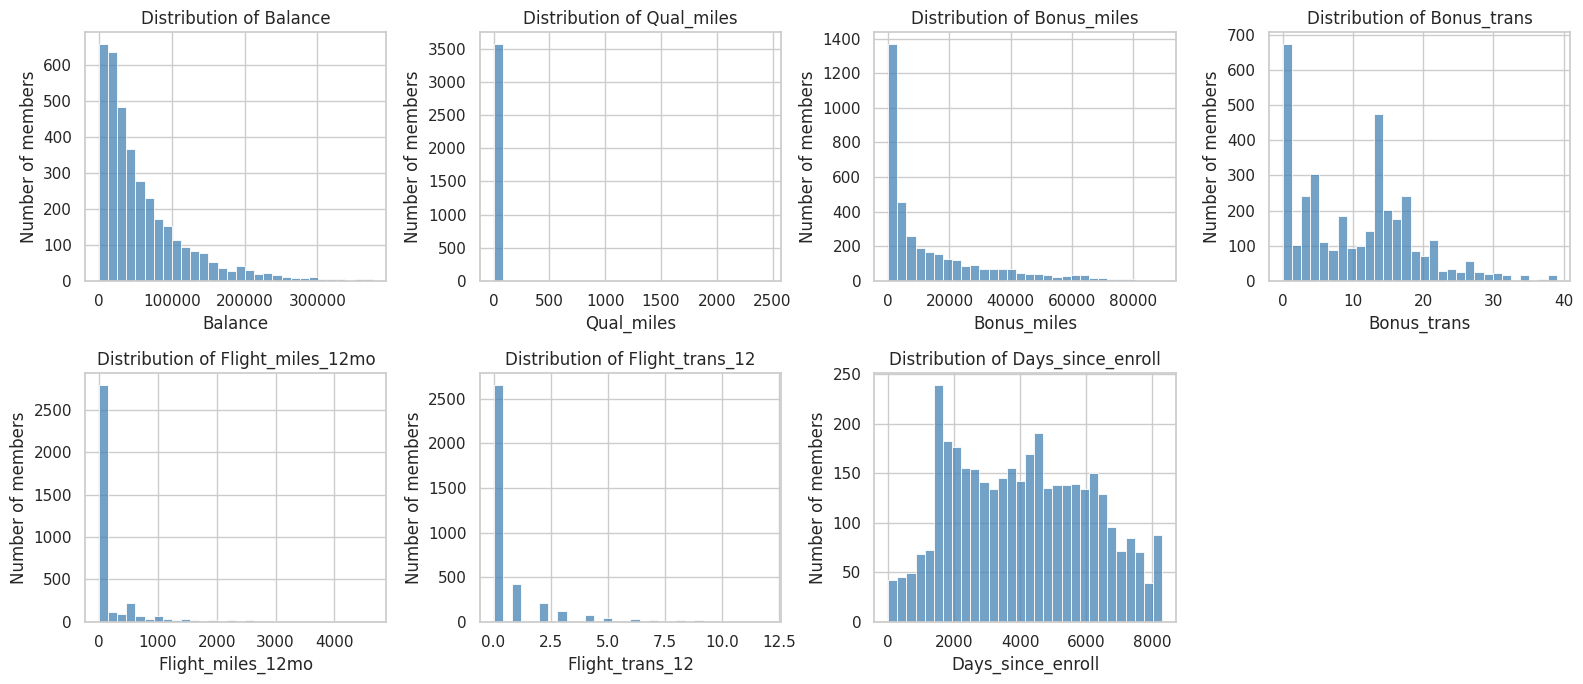

In [30]:
# Purpose: draw a histogram for each clustering feature
fig, axes = plt.subplots(2, 4, figsize=(16, 7)); axes = axes.ravel()
for ax, c in zip(axes, feats):
    sns.histplot(air_c[c], bins=30, color='steelblue', ax=ax)
    ax.set_title(f'Distribution of {c}'); ax.set_xlabel(c); ax.set_ylabel('Number of members')
axes[-1].axis('off')
plt.tight_layout(); plt.savefig('figures/cs2_histograms.png', dpi=130); plt.show()

**What the histograms show.** Qual_miles, Flight_miles_12mo and Flight_trans_12 have a very tall bar at zero. This means most members earn almost nothing from flights. Balance, Bonus_miles and Bonus_trans also have a long tail on the right side. Days_since_enroll is spread fairly evenly, which shows that members joined at a steady pace over the years. Many zeros together with a long tail suggest a large group of low-activity members and a few smaller groups of very active members.

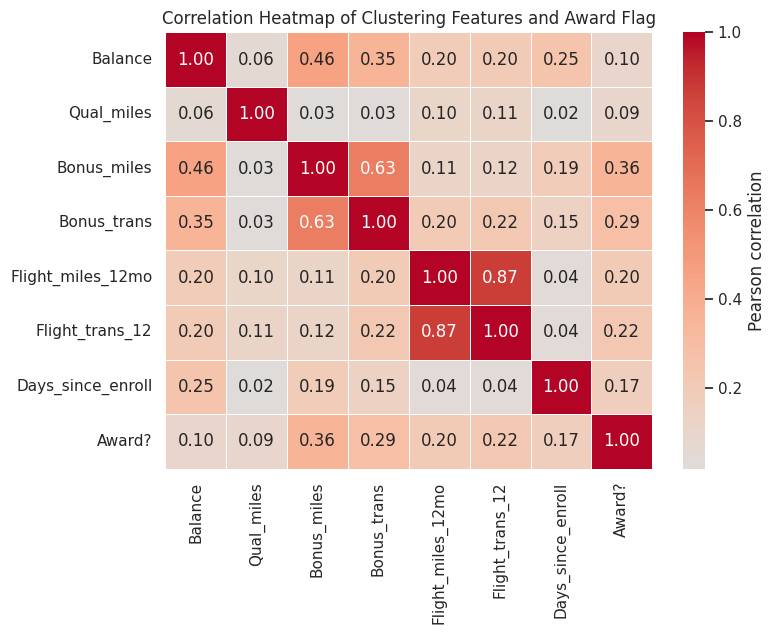

In [31]:
# Purpose: draw a correlation heatmap of the features and the Award flag
plt.figure(figsize=(8, 6.5))
sns.heatmap(air_c[feats + ['Award?']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5, cbar_kws={'label': 'Pearson correlation'})
plt.title('Correlation Heatmap of Clustering Features and Award Flag')
plt.tight_layout(); plt.savefig('figures/cs2_correlation.png', dpi=130); plt.show()

**What the heatmap shows.** Two pairs of features move together. Flight_miles_12mo and Flight_trans_12 are strongly related (r = 0.87), and Bonus_miles and Bonus_trans are fairly related (r = 0.63). The flight features and the bonus features are only weakly related to each other (r around 0.1 to 0.2). So members seem to earn miles in different ways, which supports the idea of separate groups. Qual_miles is almost unrelated to the others (r is at most 0.11). The Award flag is most linked with Bonus_miles (0.36) and Bonus_trans (0.29).

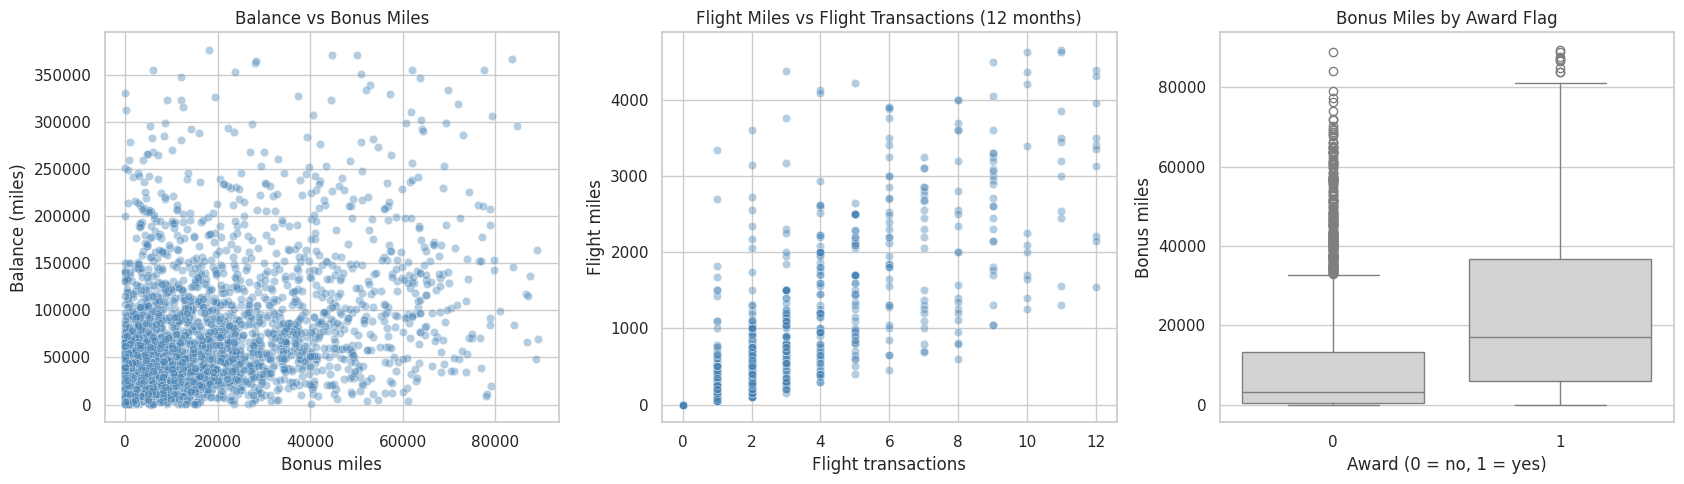

In [32]:
# Purpose: scatter plots and a box plot to look for hidden patterns
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.scatterplot(data=air_c, x='Bonus_miles', y='Balance', alpha=.4, color='steelblue', ax=axes[0])
axes[0].set_title('Balance vs Bonus Miles'); axes[0].set_xlabel('Bonus miles'); axes[0].set_ylabel('Balance (miles)')
sns.scatterplot(data=air_c, x='Flight_trans_12', y='Flight_miles_12mo', alpha=.4, color='steelblue', ax=axes[1])
axes[1].set_title('Flight Miles vs Flight Transactions (12 months)'); axes[1].set_xlabel('Flight transactions'); axes[1].set_ylabel('Flight miles')
sns.boxplot(data=air_c, x='Award?', y='Bonus_miles', color='lightgray', ax=axes[2])
axes[2].set_title('Bonus Miles by Award Flag'); axes[2].set_xlabel('Award (0 = no, 1 = yes)'); axes[2].set_ylabel('Bonus miles')
plt.tight_layout(); plt.savefig('figures/cs2_scatter.png', dpi=130); plt.show()

**What these plots show.** In the first plot, many members sit close to the origin with a low balance and few bonus miles, and a smaller number spread out towards high values. The second plot is almost a straight line, so flight miles grow with the number of flights, with a few heavy flyers far away from the rest. In the third plot, members who have taken an award have a much higher middle value of bonus miles (about 17,100) than members who have not (about 3,200). Together, these plots suggest low-activity members, members who earn mostly bonus miles, and members who fly a lot.

## 1.5 K-Means Clustering

 K  Inertia  Silhouette
 2  19993.0       0.333
 3  15745.0       0.302
 4  13008.0       0.316
 5  11368.0       0.243
 6  10195.0       0.247
 7   9348.0       0.255
 8   8698.0       0.259


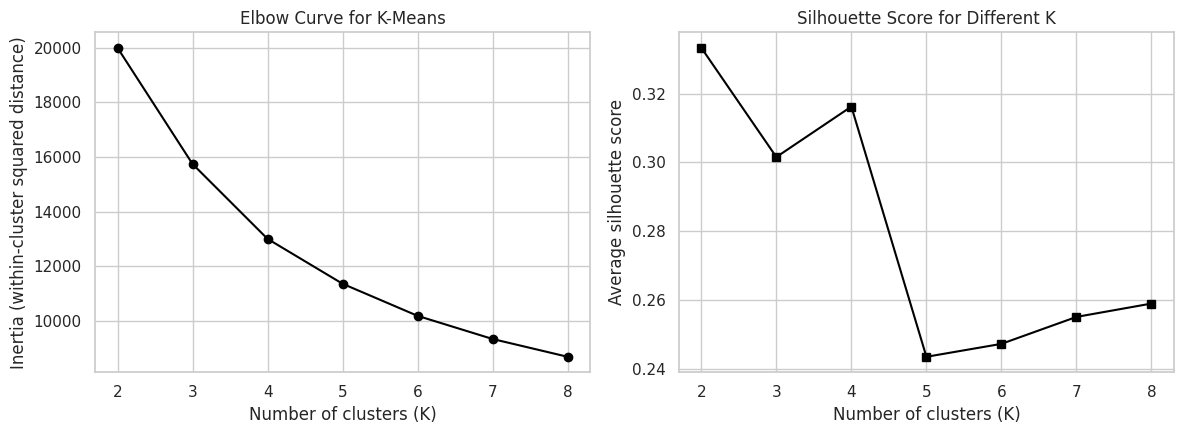

In [33]:
# Purpose: draw the elbow curve and silhouette scores for K = 2 to 8
ks = range(2, 9); inertia, sil = [], []
for k in ks:
    km_try = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Xa)
    inertia.append(km_try.inertia_); sil.append(silhouette_score(Xa, km_try.labels_))
print(pd.DataFrame({'K': list(ks), 'Inertia': np.round(inertia), 'Silhouette': np.round(sil, 3)}).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(ks, inertia, 'o-', color='black'); ax[0].set_title('Elbow Curve for K-Means'); ax[0].set_xlabel('Number of clusters (K)'); ax[0].set_ylabel('Inertia (within-cluster squared distance)')
ax[1].plot(ks, sil, 's-', color='black'); ax[1].set_title('Silhouette Score for Different K'); ax[1].set_xlabel('Number of clusters (K)'); ax[1].set_ylabel('Average silhouette score')
plt.tight_layout(); plt.savefig('figures/cs2_elbow.png', dpi=130); plt.show()

**Choosing K.** The inertia drops quickly until K = 4 and then flattens (13,008 at K = 4 and 11,368 at K = 5). So the elbow is around K = 3 to 4. The silhouette score is highest at K = 2 (0.333), followed by K = 4 (0.316) and K = 3 (0.302), and it falls to about 0.25 for K = 5 and above. K = 2 only separates active members from less active ones, which is too simple to be useful for planning offers. I chose **K = 4** because it is at the elbow, it has the second best silhouette score, and it brings out a small group of unusual members that K = 2 and K = 3 hide.

In [34]:
# Purpose: fit K-Means with K = 4 and describe each cluster using average values in original units
km = KMeans(n_clusters=4, n_init=10, random_state=42).fit(Xa)
air_c['KMeans'] = km.labels_
print('K-Means (K = 4) silhouette score: %.3f' % silhouette_score(Xa, km.labels_))

def profile(labels):
    t = air_c.assign(cluster=labels)
    g = t.groupby('cluster')[feats + ['Award?']].mean().round(2)
    g['members'] = t.groupby('cluster').size()
    g['% of members'] = (g['members'] / len(t) * 100).round(1)
    return g
profile(air_c['KMeans'])

K-Means (K = 4) silhouette score: 0.316


,Balance,Qual_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,members,% of members
cluster,,,,,,,,,,
0,96519.19,58.30,21062.37,16.53,2203.88,6.22,4356.58,0.61,247,6.7
1,103648.06,3.28,31451.67,17.48,141.86,0.47,4939.11,0.48,1193,32.4
2,32024.52,3.03,4217.86,6.01,90.86,0.32,3532.74,0.22,2162,58.8
3,77153.45,1579.21,15308.26,11.11,444.70,1.47,4323.29,0.62,76,2.1


PCA explained variance: PC1 = 34.6%, PC2 = 22.4%, together = 56.9%


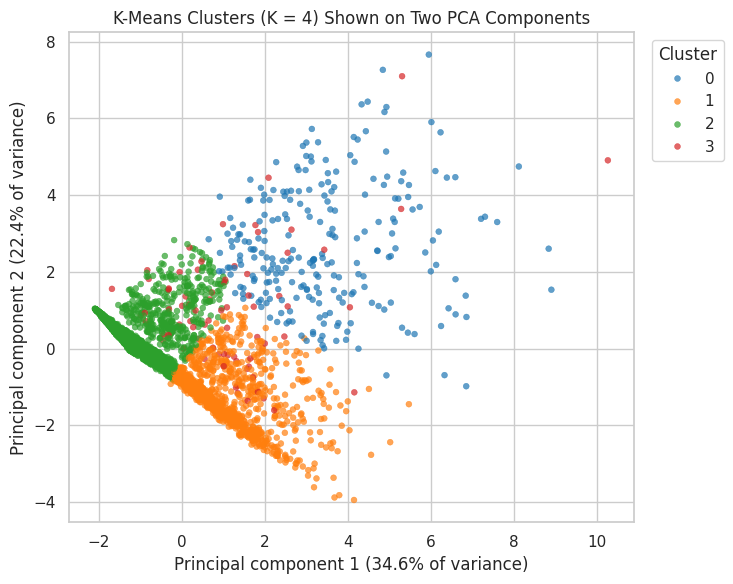

In [35]:
# Purpose: reduce the data to two dimensions with PCA so the clusters can be plotted
pca = PCA(n_components=2).fit(Xa); P = pca.transform(Xa)
print('PCA explained variance: PC1 = %.1f%%, PC2 = %.1f%%, together = %.1f%%' % (*(pca.explained_variance_ratio_*100), pca.explained_variance_ratio_.sum()*100))

def plot_pca(labels, title, fname):
    plt.figure(figsize=(7.5, 6))
    sns.scatterplot(x=P[:,0], y=P[:,1], hue=labels, palette='tab10', s=18, alpha=.7, edgecolor=None)
    plt.title(title)
    plt.xlabel('Principal component 1 (%.1f%% of variance)' % (pca.explained_variance_ratio_[0]*100))
    plt.ylabel('Principal component 2 (%.1f%% of variance)' % (pca.explained_variance_ratio_[1]*100))
    plt.legend(title='Cluster', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout(); plt.savefig(fname, dpi=130); plt.show()

plot_pca(km.labels_, 'K-Means Clusters (K = 4) Shown on Two PCA Components', 'figures/cs2_kmeans_clusters.png')

**About the plot.** It is not possible to draw seven features on a flat page, so PCA squeezes them into two new axes. These two axes keep 56.9% of the information. The first axis mostly measures overall activity, and the second axis separates members who fly a lot from members who mainly earn bonus miles. Because a part of the information is lost, the clusters overlap a little in the picture, which matches the modest silhouette score of 0.316.

**The four K-Means clusters.**

- **Cluster 2: low-activity members (2,162 members, 58.8%).** They have the smallest balance (about 32,000 miles), few bonus miles (about 4,200), about 6 bonus transactions, almost no flying, the shortest time in the programme (about 3,530 days) and the lowest award rate (22%). Suggested action: welcome offers and card or partner promotions to increase their activity.
- **Cluster 1: bonus-mile collectors (1,193 members, 32.4%).** They have the highest balance (about 104,000) and bonus miles (about 31,000) and about 17.5 bonus transactions, but they hardly fly (about 142 flight miles). They have been members the longest (about 4,940 days) and 48% have taken an award. Suggested action: redemption offers and rewards that encourage them to start flying.
- **Cluster 0: frequent flyers (247 members, 6.7%).** They fly about 2,200 miles in 12 months with about 6.2 flight transactions. Their balance is high (about 96,500) and 61% have taken an award. These are the most valuable flyers. Suggested action: loyalty tiers and premium services.
- **Cluster 3: qualifying-miles members (76 members, 2.1%).** Their main feature is a very high Qual_miles value (about 1,579, compared with 3 to 58 in the other clusters). Their balance is medium (about 77,000) and 62% have taken an award. This is a small special group, probably members who work towards a higher status. Suggested action: status-related offers.

## 1.6 Hierarchical Clustering

 linkage  K  silhouette         cluster sizes
    ward  3       0.209     [1991, 217, 1470]
    ward  4       0.232 [1899, 92, 1470, 217]
complete  3       0.543         [3586, 89, 3]
complete  4       0.496    [255, 89, 3, 3331]
 average  3       0.628         [3617, 1, 60]
 average  4       0.588     [60, 19, 3598, 1]
  single  3       0.695          [3675, 1, 2]
  single  4       0.618       [3674, 1, 2, 1]


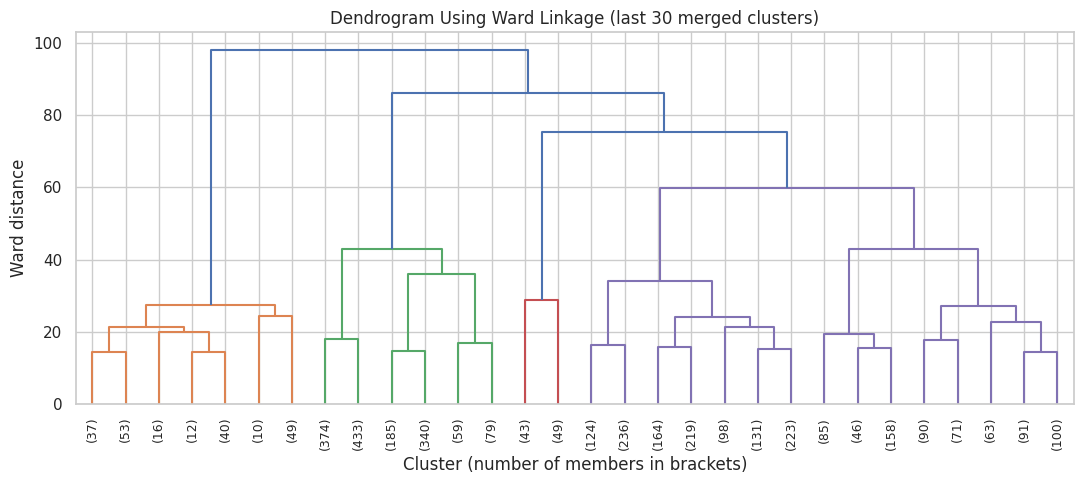

In [36]:
# Purpose: try four linkage types and draw the dendrogram for Ward linkage
rows = []
for link in ['ward', 'complete', 'average', 'single']:
    for k in (3, 4):
        lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit_predict(Xa)
        rows.append({'linkage': link, 'K': k, 'silhouette': round(silhouette_score(Xa, lab), 3), 'cluster sizes': np.bincount(lab).tolist()})
print(pd.DataFrame(rows).to_string(index=False))

Zlink = linkage(Xa, method='ward')
plt.figure(figsize=(11, 5))
dendrogram(Zlink, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9, color_threshold=0.7*max(Zlink[:,2]))
plt.title('Dendrogram Using Ward Linkage (last 30 merged clusters)')
plt.xlabel('Cluster (number of members in brackets)'); plt.ylabel('Ward distance')
plt.tight_layout(); plt.savefig('figures/cs2_dendrogram.png', dpi=130); plt.show()

**Comparing linkage types.** Single, average and complete linkage show higher silhouette scores (between 0.50 and 0.70), but this is misleading. They put almost all members into one huge cluster and make a few clusters with only 1 to 3 members. For example, single linkage with K = 4 gives sizes 3,674, 1, 2 and 1. Ward linkage gives clusters of useful sizes (1,899, 92, 1,470 and 217 for K = 4), although its silhouette score is lower (0.232). I therefore used Ward linkage.

**Dendrogram.** The joining distances increase slowly (about 60 when going from 5 to 4 clusters, 75 from 4 to 3 and 86 from 3 to 2). There is no single big gap, so the tree supports a cut at around 4 clusters but does not prove it. I used K = 4 so that the result can be compared with K-Means.

Hierarchical (Ward, K = 4) silhouette score: 0.232


,Balance,Qual_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,members,% of members
cluster,,,,,,,,,,
0,81543.08,0.26,22836.39,15.57,121.46,0.41,4343.33,0.41,1899,51.6
1,73472.26,1386.68,14133.48,10.28,416.88,1.28,4226.98,0.57,92,2.5
2,27195.64,0.00,2340.37,2.97,119.02,0.43,3657.98,0.19,1470,40.0
3,96800.49,77.41,22579.44,17.98,2303.55,6.33,4242.81,0.64,217,5.9


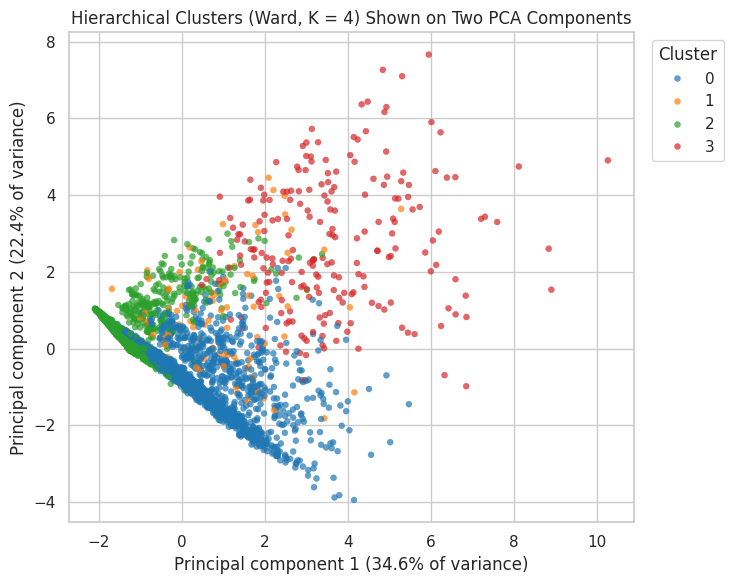

In [37]:
# Purpose: fit Ward hierarchical clustering with K = 4 and describe each cluster
hc = AgglomerativeClustering(n_clusters=4, linkage='ward').fit(Xa)
air_c['Hierarchical'] = hc.labels_
print('Hierarchical (Ward, K = 4) silhouette score: %.3f' % silhouette_score(Xa, hc.labels_))
display(profile(air_c['Hierarchical']))
plot_pca(hc.labels_, 'Hierarchical Clusters (Ward, K = 4) Shown on Two PCA Components', 'figures/cs2_hierarchical_clusters.png')

**The four hierarchical clusters.** The groups are similar to the K-Means groups, but not identical.

- **Cluster 2 (1,470 members, 40.0%)** contains low-activity members (balance about 27,000, about 3 bonus transactions, award rate 19%). It matches K-Means cluster 2.
- **Cluster 0 (1,899 members, 51.6%)** is a large middle group with a good balance (about 81,500) and plenty of bonus miles (about 22,800), but almost no flying. It joins together what K-Means kept as the bonus-mile collectors and a part of the low-activity members.
- **Cluster 3 (217 members, 5.9%)** contains frequent flyers (about 2,300 flight miles, award rate 64%). It matches K-Means cluster 0.
- **Cluster 1 (92 members, 2.5%)** is the qualifying-miles group (Qual_miles about 1,387). It matches K-Means cluster 3.

Both methods agree on the three special groups (low activity, frequent flyers and qualifying miles). They differ mainly in how they split the large middle part of the members.

## 1.7 DBSCAN

k-distance at the 50th, 75th, 90th, 95th and 99th percentile: [0.47 0.83 1.4  1.92 3.1 ]


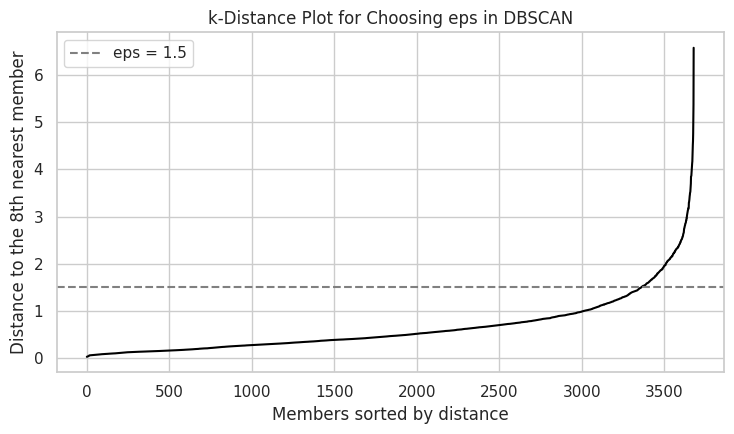

 eps  min_samples  clusters  noise points  silhouette (without noise)
 0.3            5        19          2079                      -0.293
 0.3           10         3          2386                       0.246
 0.5            5        17          1233                      -0.324
 0.5           10         2          1545                      -0.043
 0.7            5         7           761                       0.012
 0.7           10         3           987                       0.119
 1.0            5         2           437                       0.526
 1.0           10         1           512                         NaN
 1.5            5         3           166                       0.364
 1.5           10         2           221                       0.359


In [38]:
# Purpose: draw the k-distance plot and try different eps and min_samples values
nn = NearestNeighbors(n_neighbors=8).fit(Xa)
kd = np.sort(nn.kneighbors(Xa)[0][:, -1])
print('k-distance at the 50th, 75th, 90th, 95th and 99th percentile:', np.percentile(kd, [50, 75, 90, 95, 99]).round(2))
plt.figure(figsize=(7.5, 4.5)); plt.plot(kd, color='black'); plt.axhline(1.5, ls='--', color='gray', label='eps = 1.5')
plt.title('k-Distance Plot for Choosing eps in DBSCAN'); plt.xlabel('Members sorted by distance'); plt.ylabel('Distance to the 8th nearest member'); plt.legend()
plt.tight_layout(); plt.savefig('figures/cs2_kdistance.png', dpi=130); plt.show()

rows = []
for eps in (0.3, 0.5, 0.7, 1.0, 1.5):
    for ms in (5, 10):
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xa); nc = len(set(lab)) - (1 if -1 in lab else 0); ok = lab != -1
        s = round(silhouette_score(Xa[ok], lab[ok]), 3) if nc > 1 else np.nan
        rows.append({'eps': eps, 'min_samples': ms, 'clusters': nc, 'noise points': int((~ok).sum()), 'silhouette (without noise)': s})
print(pd.DataFrame(rows).to_string(index=False))

**Choosing the settings.** The k-distance curve stays low for most members and then rises steeply near the end. The bend is at a distance of about 1 to 1.5. In the trial table, small eps values (0.3 and 0.5) mark 1,200 to 2,400 members as noise and break the data into many small pieces, which is not useful. With eps = 1.0 the silhouette score looks very good (0.526), but only because 437 members (12%) were set aside as noise. I chose **eps = 1.5 and min_samples = 5**, which gives 3 clusters and only 166 noise points (4.5%). Between the two settings that gave a sensible number of noise points, eps = 1.5 with min_samples = 10 gave 2 clusters and 221 noise points (silhouette 0.359). With min_samples = 5 there were 3 clusters and only 166 noise points (silhouette 0.364). I kept min_samples = 5 because it sets aside fewer members and keeps one more small group visible. A drawback is that min_samples = 5 is below the common guideline of at least the number of features plus one (here 8), so the two tiny clusters should be treated with caution. Note that the silhouette score for DBSCAN is calculated without the noise points, so it cannot be compared directly with the other two methods.

Clusters found: 3 | Noise points: 166 (4.5%)
DBSCAN silhouette score (without noise): 0.364


,Balance,Qual_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?,members,% of members
cluster,,,,,,,,,,
-1,128001.45,667.24,27586.10,18.09,1532.96,4.68,4493.55,0.68,166,4.5
0,57459.86,0.00,13846.39,10.21,197.44,0.61,4040.99,0.32,3488,94.8
1,40216.60,878.33,5336.67,5.47,39.13,0.20,4060.40,0.47,15,0.4
2,35728.89,2326.33,5679.78,7.44,11.11,0.11,3662.33,0.44,9,0.2


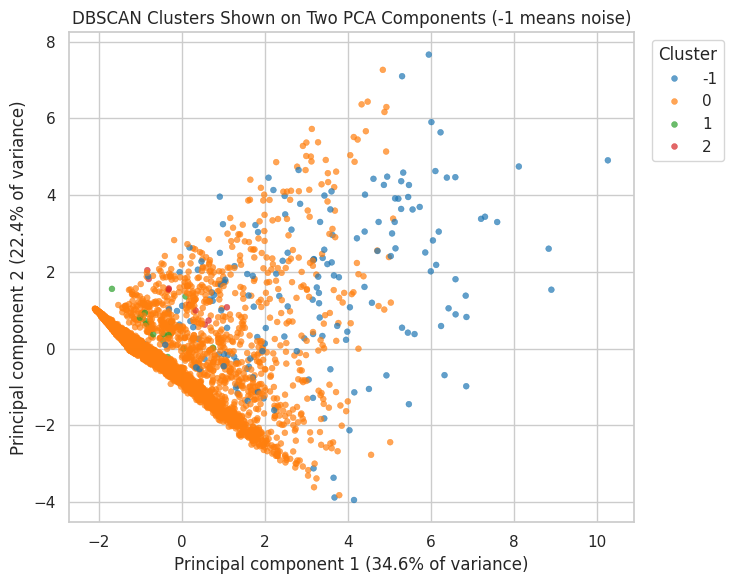

In [39]:
# Purpose: fit DBSCAN with eps = 1.5 and min_samples = 5 and describe the clusters and noise points
db = DBSCAN(eps=1.5, min_samples=5).fit(Xa)
air_c['DBSCAN'] = db.labels_; db_ok = db.labels_ != -1
print('Clusters found:', len(set(db.labels_)) - 1, '| Noise points:', (~db_ok).sum(), f'({(~db_ok).mean():.1%})')
print('DBSCAN silhouette score (without noise): %.3f' % silhouette_score(Xa[db_ok], db.labels_[db_ok]))
display(profile(air_c['DBSCAN']))
plot_pca(db.labels_, 'DBSCAN Clusters Shown on Two PCA Components (-1 means noise)', 'figures/cs2_dbscan_clusters.png')

**What DBSCAN found.** DBSCAN created one very large cluster with 94.8% of the members (3,488), two tiny clusters (15 and 9 members) and **166 noise points (4.5%)**. It does not cut the large group of ordinary members into parts, because there is no empty gap between them. Its real use here is to find unusual members. The noise points have the highest averages of all (balance about 128,000, about 27,600 bonus miles, about 1,533 flight miles, award rate 68%). These are the heaviest users of the programme and can be treated as a special VIP group. The two small clusters have a high Qual_miles value (about 880 and 2,330) and very little flying. So DBSCAN works better as a tool to find special members than as a tool to divide all members into segments.

## 1.8 Comparison of the Three Methods

In [40]:
# Purpose: put the results of the three methods in one table
comparison = pd.DataFrame([
    {'Method': 'K-Means (K = 4)', 'Clusters': 4, 'Noise points': 0, 'Silhouette score': round(silhouette_score(Xa, km.labels_), 3), 'Smallest cluster': int(np.bincount(km.labels_).min())},
    {'Method': 'Hierarchical (Ward, K = 4)', 'Clusters': 4, 'Noise points': 0, 'Silhouette score': round(silhouette_score(Xa, hc.labels_), 3), 'Smallest cluster': int(np.bincount(hc.labels_).min())},
    {'Method': 'DBSCAN (eps = 1.5, min_samples = 5)', 'Clusters': 3, 'Noise points': int((~db_ok).sum()), 'Silhouette score': round(silhouette_score(Xa[db_ok], db.labels_[db_ok]), 3), 'Smallest cluster': int(np.bincount(db.labels_[db_ok]).min())}])
comparison

,Method,Clusters,Noise points,Silhouette score,Smallest cluster
0,K-Means (K = 4),4,0,0.316,76
1,"Hierarchical (Ward, K = 4)",4,0,0.232,92
2,"DBSCAN (eps = 1.5, min_samples = 5)",3,166,0.364,9


## 1.9 Conclusion of Case Study 2
- The members mainly fall into four types: a large low-activity group, a big group that collects bonus miles but rarely flies, a small group of frequent flyers, and a very small group with high qualifying miles.
- K-Means with K = 4 gave the clearest and most useful groups, with a silhouette score of 0.316. Ward hierarchical clustering found the same main groups (0.232). DBSCAN did not split the members into segments, but it picked out 166 high-value members who behave differently from the rest.
- All silhouette scores are modest (about 0.23 to 0.32). This means the groups overlap, and members form more of a smooth range than clearly separate groups. The cluster descriptions should be read as general tendencies.
- Limitations: removing outliers took away 321 members, and some of them may be valuable customers. Also, the 2-D plots show only 56.9% of the information, and the results depend on the chosen features, K and DBSCAN settings.

# Part 2: Case Study 5 (Wine Quality)

## 2.1 Problem Statement
At present the company judges the quality of its wine only through tasting by experts. Management wants to know whether laboratory measurements of the wine can explain why some wines are rated higher than others, and whether they can help to build a data-based quality check.

In this case study I find which measurements are most connected with wine quality, and I build a regression model that predicts the quality score from the laboratory measurements.

## 2.2 Methodology
I combined the red wine file (1,599 samples) and the white wine file (4,898 samples) into one dataset of 6,497 wines. Each wine has 11 laboratory measurements and one quality score. The score is the middle value of at least three expert ratings, on a scale of 0 to 10. The work follows the four tasks of the case study: statistics, exploratory analysis, predictive modelling and business decision-making. A fixed random state of 42 was used for the train and test split so that the results can be repeated.

*Data source: P. Cortez, A. Cerdeira, F. Almeida, T. Matos and J. Reis (2009), Modeling wine preferences by data mining from physicochemical properties, Decision Support Systems, 47(4), 547-553.*

In [41]:
# Purpose: load and combine the red and white wine files, then check size, missing values and duplicates
red   = pd.read_csv('/content/sample_data/winequality-red.csv',   sep=';')
white = pd.read_csv('/content/sample_data/winequality-white.csv', sep=';')
wine = pd.concat([red, white], ignore_index=True)
print('Shape:', wine.shape)
print('Missing values:', wine.isna().sum().sum())
print('Duplicate rows:', wine.duplicated().sum())
wine.describe().T.round(3)

Shape: (6497, 12)
Missing values: 0
Duplicate rows: 1179


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


The combined data has 6,497 rows and 12 columns, with no missing values, so nothing had to be filled in. There are 1,179 duplicate rows. I kept them in the main analysis, because different bottles from the same batch can have exactly the same laboratory readings. Identical readings do not prove that two rows are the same bottle. Section 2.6 checks whether keeping them affects the model results.

## 2.3 Task 1: Statistical Analysis

In [42]:
# Purpose (Task 1a, 1b): mean, median, mode, standard deviation, skewness and coefficient of variation (CV)
cols = ['alcohol', 'volatile acidity', 'residual sugar']
rows = []
for c in cols:
    s = wine[c]
    rows.append({'attribute': c, 'mean': s.mean(), 'median': s.median(), 'mode': s.mode()[0],
                 'std dev': s.std(), 'skewness': s.skew(), 'CV (%)': s.std()/s.mean()*100})
summary = pd.DataFrame(rows).set_index('attribute').round(3)
summary

,mean,median,mode,std dev,skewness,CV (%)
attribute,,,,,,
alcohol,10.492,10.30,9.50,1.193,0.566,11.368
volatile acidity,0.340,0.29,0.28,0.165,1.495,48.470
residual sugar,5.443,3.00,2.00,4.758,1.435,87.408


**Task 1a: Reading the results.**

- *Alcohol:* the mean is 10.49, the median is 10.30 and the mode is 9.5. The skewness is 0.57, which is a mild skew to the right. Most wines have between 9.5% and 11.5% alcohol, and a few strong wines stretch the right side.
- *Volatile acidity:* the mean (0.340) is higher than the median (0.290) and the skewness is 1.50, so the distribution is clearly skewed to the right. A few wines have a very high acetic acid level, which is linked to spoilage.
- *Residual sugar:* the mean is 5.44 but the median is only 3.00 and the mode is 2.0. The skewness is 1.44. Most wines are dry, and a few sweet wines pull the average up.

**Task 1b: Which attribute varies the most?** The standard deviations cannot be compared directly because the attributes are measured in different units. So I used the coefficient of variation (CV = standard deviation divided by mean, times 100), which has no unit. Residual sugar has the highest CV (87.4%), followed by volatile acidity (48.5%) and alcohol (11.4%). Residual sugar therefore has the greatest variability relative to its average.

In [43]:
# Purpose (Task 1c): Pearson correlation between alcohol and quality
r, p = stats.pearsonr(wine['alcohol'], wine['quality'])
print(f'Pearson r (alcohol vs quality) = {r:.3f}, p-value = {p:.2e}')

Pearson r (alcohol vs quality) = 0.444, p-value = 1.50e-312


**Task 1c: Alcohol and quality.** The correlation coefficient is r = +0.444, and the p-value is practically zero. The relationship is *positive* and of *moderate* strength. Wines with more alcohol tend to receive higher quality scores. Since r squared is about 0.20, alcohol alone explains about 20% of the differences in quality. This does not prove that alcohol causes better quality. For example, grapes that ripen well can give both higher alcohol and a better taste.

## 2.4 Task 2: Exploratory Data Analysis

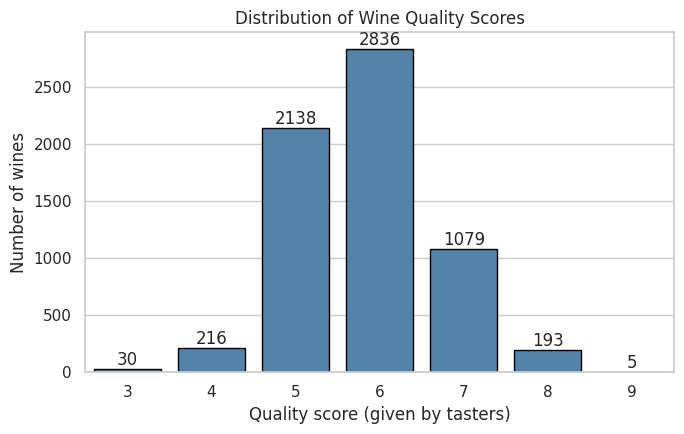

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


In [44]:
# Purpose (Task 2a): histogram (count plot) of the quality scores
plt.figure(figsize=(7, 4.5))
ax = sns.countplot(x='quality', data=wine, color='steelblue', edgecolor='black')
for bar in ax.patches:
    ax.annotate(int(bar.get_height()), (bar.get_x()+bar.get_width()/2, bar.get_height()), ha='center', va='bottom')
plt.title('Distribution of Wine Quality Scores'); plt.xlabel('Quality score (given by tasters)'); plt.ylabel('Number of wines')
plt.tight_layout(); plt.savefig('figures/cs5_quality_histogram.png', dpi=150); plt.show()
print(wine['quality'].value_counts().sort_index())

**Task 2a: Reading the histogram.** Most wines are in the middle. Scores 5 (2,138 wines) and 6 (2,836 wines) together make up about 77% of the data. Very poor wines (score 3: 30 wines) and excellent wines (score 9: only 5 wines) are rare. The shape is roughly bell-like but uneven. This is important for modelling, because the model has very few examples of the best and worst wines, so it will tend to predict scores near the middle (between 5 and 7).

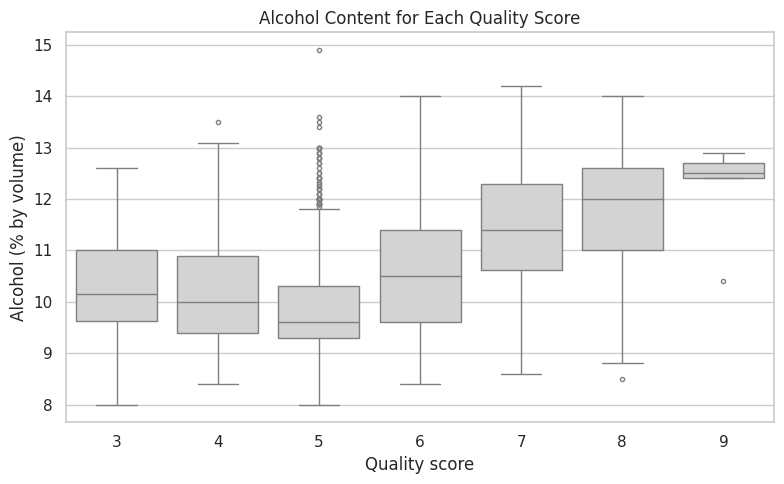

,count,median,outliers
quality,,,
3,30,10.15,0
4,216,10.00,1
5,2138,9.60,55
6,2836,10.50,0
7,1079,11.40,0
8,193,12.00,1
9,5,12.50,1


In [45]:
# Purpose (Task 2b): box plot of alcohol for each quality score, with a count of outliers per score
plt.figure(figsize=(8, 5))
sns.boxplot(x='quality', y='alcohol', data=wine, color='lightgray', fliersize=3)
plt.title('Alcohol Content for Each Quality Score'); plt.xlabel('Quality score'); plt.ylabel('Alcohol (% by volume)')
plt.tight_layout(); plt.savefig('figures/cs5_alcohol_boxplot.png', dpi=150); plt.show()

def count_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return ((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum()
table = wine.groupby('quality')['alcohol'].agg(['count', 'median'])
table['outliers'] = wine.groupby('quality')['alcohol'].apply(count_outliers)
table

**Task 2b: Reading the box plot.** The middle alcohol value is lowest for quality 5 (9.6%) and then rises with quality: 10.5% for quality 6, 11.4% for 7, 12.0% for 8 and 12.5% for 9. So from quality 5 upwards, better wines clearly have more alcohol. The lowest scores (3 and 4) do not follow this pattern. Their middle values are 10.15% and 10.0%, which are higher than for quality 5, so the link is not perfectly steady. Most of the outliers (points far from the box) are in quality 5, with 55 points, mostly wines with unusually high alcohol. All the other scores have at most one outlier. These look like genuine measurements and not mistakes, so I kept them. The groups for scores 3, 8 and 9 are small, so their boxes are less dependable.

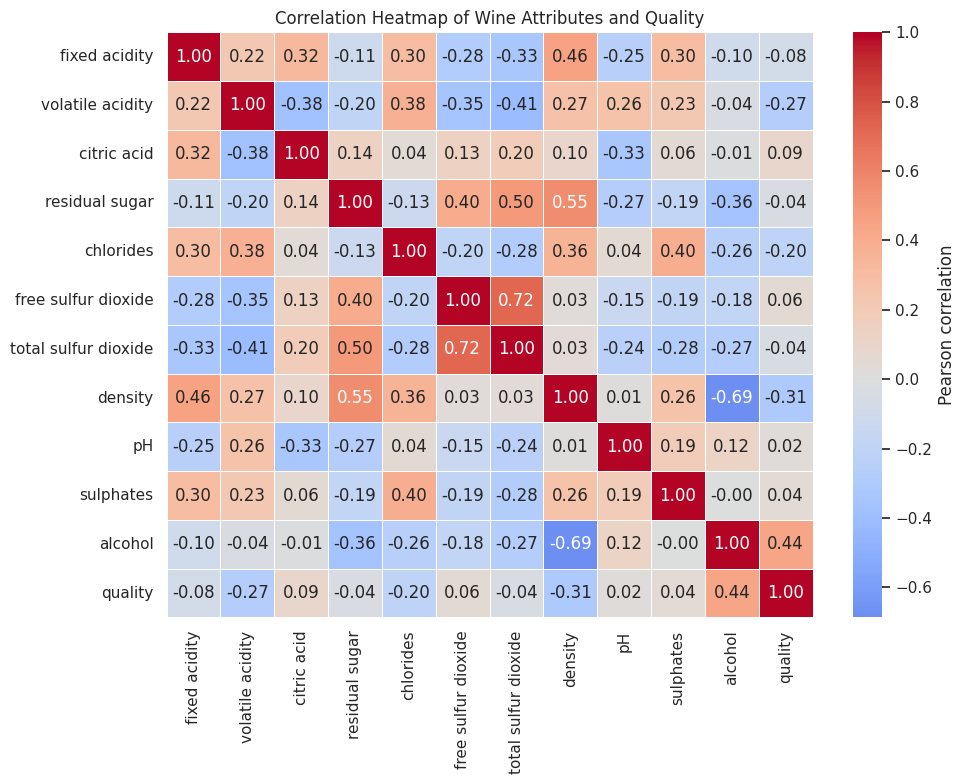

alcohol                 0.444
density                -0.306
volatile acidity       -0.266
chlorides              -0.201
citric acid             0.086
fixed acidity          -0.077
free sulfur dioxide     0.055
total sulfur dioxide   -0.041
sulphates               0.038
residual sugar         -0.037
pH                      0.020
Name: quality, dtype: float64


In [46]:
# Purpose (Task 2c, 2d): correlation heatmap and ranking of attributes by correlation with quality
plt.figure(figsize=(10, 8))
sns.heatmap(wine.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=.5, cbar_kws={'label': 'Pearson correlation'})
plt.title('Correlation Heatmap of Wine Attributes and Quality')
plt.tight_layout(); plt.savefig('figures/cs5_correlation_heatmap.png', dpi=150); plt.show()

qcorr = wine.corr()['quality'].drop('quality')
print(qcorr.reindex(qcorr.abs().sort_values(ascending=False).index).round(3))

**Task 2c and 2d: Reading the heatmap.** When the attributes are ranked by the size of their correlation with quality, alcohol is first (+0.444), followed by density (-0.306), volatile acidity (-0.266) and chlorides (-0.201). All other attributes have a correlation below 0.09, so on their own they say very little about quality.

The two attributes most strongly connected with quality are:

- **Alcohol**, with a *positive* relationship. Higher alcohol goes with higher quality.
- **Density**, with a *negative* relationship. Denser wines tend to get lower scores. Density mostly depends on alcohol and sugar (its correlation with alcohol is -0.69), so it is not an independent factor.

The heatmap also shows that some measurements are strongly related to each other, for example free and total sulfur dioxide (r = 0.72) and density with residual sugar (r = 0.55). This is a warning about multicollinearity, which is discussed in Task 3.

## 2.5 Task 3: Predictive Modelling (Multiple Linear Regression)

In [47]:
# Purpose (Task 3a to 3c): 80/20 split, fit multiple linear regression and find MAE, MSE, RMSE and R2 on the test set
X = wine.drop(columns='quality'); y = wine['quality']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print('Training rows:', X_train.shape[0], '| Testing rows:', X_test.shape[0])

model = LinearRegression().fit(X_train, y_train)
y_pred = model.predict(X_test)

mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2   = r2_score(y_test, y_pred)
print(f'MAE  = {mae:.4f}\nMSE  = {mse:.4f}\nRMSE = {rmse:.4f}\nR2   = {r2:.4f}')

baseline = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
print(f'MAE if we always guess the average training score = {baseline:.4f}')
print(f'Predictions within 0.5 of the true score: {np.mean(abs(y_pred-y_test)<=0.5):.1%}')
print(f'Predictions within 1.0 of the true score: {np.mean(abs(y_pred-y_test)<=1):.1%}')

Training rows: 5197 | Testing rows: 1300
MAE  = 0.5659
MSE  = 0.5467
RMSE = 0.7394
R2   = 0.2598
MAE if we always guess the average training score = 0.6691
Predictions within 0.5 of the true score: 53.9%
Predictions within 1.0 of the true score: 84.2%


**Task 3b and 3c: Reading the metrics.** The data was split into 5,197 wines for training and 1,300 wines for testing (random state 42). On the test wines, which the model had not seen, the results are MAE = 0.566, MSE = 0.547, RMSE = 0.739 and R squared = 0.260.

- On average, the prediction is wrong by about 0.57 points. A simple guess of the average score has an MAE of 0.669, so the model is only a little better than guessing.
- R squared of 0.26 means the 11 measurements explain only about 26% of the differences in wine quality. The remaining 74% depends on things not present in the data, such as taste, aroma and the opinions of the tasters.
- About 54% of the predictions are within half a point of the real score, and about 84% are within one point. Since the score is a whole number, an error of half a point is often enough to give the wrong grade.

Standardised coefficients:
 alcohol                 0.322
residual sugar          0.220
volatile acidity       -0.219
density                -0.177
total sulfur dioxide   -0.150
free sulfur dioxide     0.123
sulphates               0.120
fixed acidity           0.102
pH                      0.077
citric acid            -0.021
chlorides              -0.012
dtype: float64

Variance Inflation Factors (VIF):
 density                 15.51
residual sugar           7.20
fixed acidity            4.74
alcohol                  4.62
total sulfur dioxide     2.96
pH                       2.47
free sulfur dioxide      2.16
volatile acidity         1.94
chlorides                1.65
citric acid              1.61
sulphates                1.54
dtype: float64


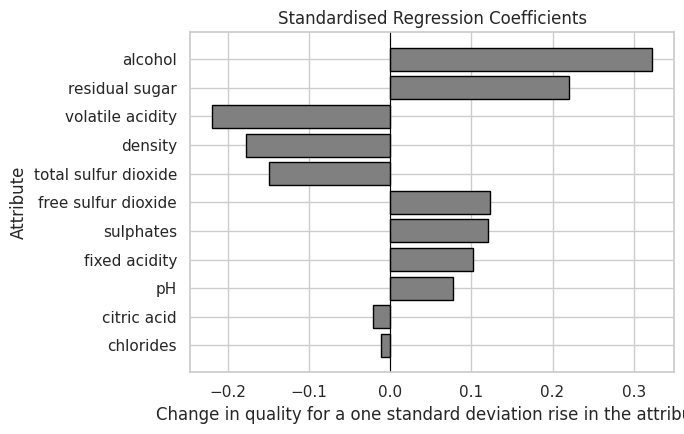

In [48]:
# Purpose (Task 3d): standardised coefficients to compare predictors, and VIF to check multicollinearity
scaler = StandardScaler().fit(X_train)
model_std = LinearRegression().fit(scaler.transform(X_train), y_train)
std_coef = pd.Series(model_std.coef_, index=X.columns)
std_coef = std_coef.reindex(std_coef.abs().sort_values(ascending=False).index)
print('Standardised coefficients:\n', std_coef.round(3))

Xc = np.column_stack([np.ones(len(X_train)), X_train.values])
vif = pd.Series([variance_inflation_factor(Xc, i+1) for i in range(X.shape[1])], index=X.columns).sort_values(ascending=False)
print('\nVariance Inflation Factors (VIF):\n', vif.round(2))

plt.figure(figsize=(7, 4.5))
plt.barh(std_coef.index[::-1], std_coef.values[::-1], color='gray', edgecolor='black')
plt.axvline(0, color='black', lw=.8)
plt.title('Standardised Regression Coefficients'); plt.xlabel('Change in quality for a one standard deviation rise in the attribute'); plt.ylabel('Attribute')
plt.tight_layout(); plt.savefig('figures/cs5_standardised_coefficients.png', dpi=150); plt.show()

**Task 3d: Most influential predictors.** After putting all attributes on the same scale, the largest coefficients are alcohol (+0.322), residual sugar (+0.220) and volatile acidity (-0.219). The last two are almost equal. Taking the top two strictly by size gives **alcohol and residual sugar**, but volatile acidity is just as important as residual sugar.

**Checking multicollinearity.** The variance inflation factor (VIF) shows how much an attribute overlaps with the others. A value above 5 is a concern and above 10 is serious. Density has a VIF of 15.5 and residual sugar has 7.2, while fixed acidity (4.7) and alcohol (4.6) are moderate. Density is mostly a mixture of alcohol and sugar, so the coefficients of these attributes are not stable and have to be read with care.

An example is residual sugar. On its own it has almost no correlation with quality (-0.037), yet its coefficient in the model is positive (+0.220). This happens because density has a negative coefficient and rises with sugar, so once density is held fixed the model passes part of its effect to sugar. Therefore, we should not conclude that sugar improves wine. The effect of alcohol is the most trustworthy because it is positive in both the correlation and the model. The effect of volatile acidity is also reliable, since its VIF is low (1.9) and its sign is always negative.

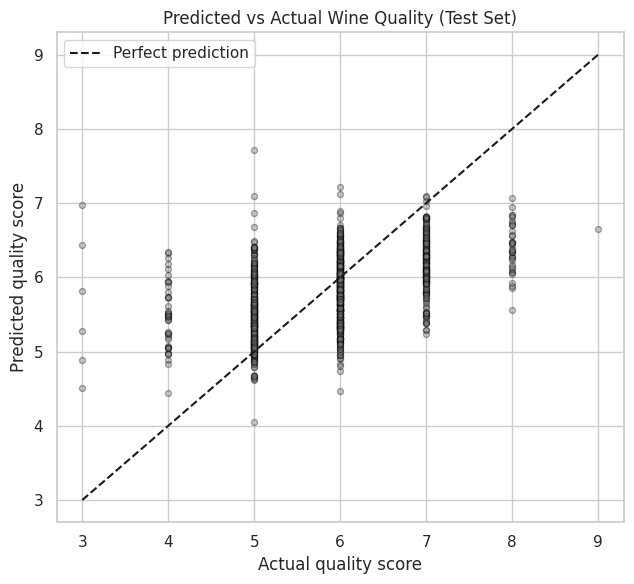

Predictions range from 4.05 to 7.72


In [49]:
# Purpose (Task 3e): scatter plot of predicted versus actual quality on the test set
plt.figure(figsize=(6.5, 6))
plt.scatter(y_test, y_pred, alpha=.35, color='gray', edgecolor='black', s=18)
plt.plot([3, 9], [3, 9], 'k--', label='Perfect prediction')
plt.title('Predicted vs Actual Wine Quality (Test Set)'); plt.xlabel('Actual quality score'); plt.ylabel('Predicted quality score')
plt.legend(); plt.tight_layout(); plt.savefig('figures/cs5_predicted_vs_actual.png', dpi=150); plt.show()
print('Predictions range from', y_pred.min().round(2), 'to', y_pred.max().round(2))

**Task 3e: Predicted against actual scores.** If the model were perfect, all points would lie on the dashed line. Instead, the points form a wide band. The predictions only range from about 4.1 to 7.7, while the real scores range from 3 to 9. The model predicts poor wines (3 and 4) to be better than they are, and excellent wines (8 and 9) to be worse than they are, so everything is pulled towards the middle.

Limitations of the model:

1. It assumes a straight-line relationship, but the real relationship may be curved.
2. Quality is a whole-number score, while the model gives decimal values.
3. Multicollinearity makes the coefficients of individual attributes unstable.
4. There are very few samples of the lowest and highest quality.
5. Red and white wines are mixed together, although their chemistry is different.

## 2.6 Extra Check: Duplicate Rows and Wine Type

In [50]:
# Purpose (extra check): repeat the model after removing duplicate rows, and after adding a red/white wine type column
red['wine_type'] = 0; white['wine_type'] = 1
wine_t = pd.concat([red, white], ignore_index=True)
feats11 = list(X.columns)

# how many test wines in the main model have an identical twin in the training set?
train_keys = set(map(tuple, X_train.round(6).values))
share_twin = np.mean([tuple(row) in train_keys for row in X_test.round(6).values])
print(f'Test wines that also appear in the training set: {share_twin:.1%}')

def evaluate(data, cols, name):
    Xs, ys = data[cols], data['quality']
    Xtr, Xte, ytr, yte = train_test_split(Xs, ys, test_size=0.2, random_state=42)
    pred = LinearRegression().fit(Xtr, ytr).predict(Xte)
    mse_ = mean_squared_error(yte, pred)
    return {'Model': name, 'Rows used': len(data), 'Test rows': len(yte), 'MAE': round(mean_absolute_error(yte, pred), 3),
            'MSE': round(mse_, 3), 'RMSE': round(np.sqrt(mse_), 3), 'R2': round(r2_score(yte, pred), 3)}

unique = wine_t.drop_duplicates(subset=feats11 + ['quality']).reset_index(drop=True)
check = pd.DataFrame([
    evaluate(wine_t, feats11, 'Main model (all rows, 11 attributes)'),
    evaluate(unique, feats11, 'Duplicates removed, 11 attributes'),
    evaluate(wine_t, feats11 + ['wine_type'], 'All rows, 11 attributes + wine type'),
    evaluate(unique, feats11 + ['wine_type'], 'Duplicates removed + wine type')])
check

Test wines that also appear in the training set: 27.6%


,Model,Rows used,Test rows,MAE,MSE,RMSE,R2
0,"Main model (all rows, 11 attributes)",6497,1300,0.566,0.547,0.739,0.260
1,"Duplicates removed, 11 attributes",5318,1064,0.552,0.510,0.714,0.321
2,"All rows, 11 attributes + wine type",6497,1300,0.564,0.541,0.736,0.267
3,Duplicates removed + wine type,5318,1064,0.552,0.507,0.712,0.324
